![Banner](../../../../Images/Banner/07_remote_sensing/09_04_banner_rs_uav.png)


# Plant Counting and Size

Stand counts tell a breeder or agronomist how well a crop established, and plant size shows
how evenly it grows.


## Overview

Early in the season, before canopies merge, plants can be counted
from millimetre-resolution drone imagery. This notebook counts transplanted rice hills in
the LUMS frames two ways: a **classical** approach (local maxima of Excess Green with
`rs.uav.count_plants`), and the **deep-learning** approach of the LUMS paper (RiceNet density
regression with `rs.uav.density_count`). Both run tile by tile on large images, so the
notebook also covers overlapping tiles, cosine-weighted stitching and merging duplicate
detections across tiles.


## Core concepts

### Learning objectives

1. Detect plants as peaks or blobs of a vegetation index, with distances set in metres.
2. See how sensitive counts are to the minimum spacing, and choose it from agronomy.
3. Tile a large image with overlap, stitch tile outputs with cosine weights, and merge
   duplicate points (`sliding_windows`, `predict_tiled`, `merge_points`).
4. Estimate per-plant size and assign size classes (`size_classes`).
5. Compute plant density per area unit (`plants_per_area`).
6. Run RiceNet density counting when its weights are available.

### Data

| Data | Type |
|---|---|
| LUMS rice frames, 22 Aug 2025, 1.85 mm/px (`Data/08_remote_sensing/08_04_uav/infrastructure-free-uav-phenotyping/2025-08-22`) | **Real** (CC BY 4.0) |
| 13 Aug orthomosaic and the paper's manual plant counts | Not in the public release. Counts here are checked by eye and between methods |

### Contents

1. Setup
2. Classical counting: peaks of Excess Green
3. Large images: tiles, stitching and merging
4. Plant size
5. Plants per square metre
6. Two dates compared
7. RiceNet density counting
8. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # plot polygons
import matplotlib.pyplot as plt  # figures
from shapely.geometry import box  # rectangles

import geolattice.rsense as rs  # GeoLattice remote sensing (rs.uav = drone tools)

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
LUMS = Path("../../../../Data/08_remote_sensing/08_04_uav/infrastructure-free-uav-phenotyping")
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
GSD = 0.00185  # m/px of the 6 m LUMS frames
RUN_DL = False  # True: download RiceNet weights (Google Drive, via gdown) and run density counting

frames = sorted((LUMS / "2025-08-22").glob("*.png"))
print(len(frames), "frames from 22 Aug 2025")

10 frames from 22 Aug 2025


## Classical counting: peaks of Excess Green

Each rice hill is a cluster of green leaves. Smoothing ExG with a Gaussian of a few
centimetres merges the leaves of one hill into a single bump; local maxima at least
`min_distance_m` apart above an Otsu threshold become plants. Because the frame is read with
its GSD, both distances are given in metres.


In [2]:
img = rs.uav.read_frame(frames[3], gsd=GSD, max_dim=1920)  # half resolution: 3.7 mm/px
gsd = img.attrs["gsd_m"]
exg = rs.uav.vegetation_indices(img, "ExG")
pts = rs.uav.count_plants(exg, min_distance_m=0.15, sigma_m=0.03, gsd=gsd)
print(len(pts), "plants;", f"GSD {gsd * 1000:.1f} mm")
pts.head()

169 plants; GSD 3.7 mm


,value,row,col,geometry
0,0.650980,836,69,POINT (0.25715 -3.09505)
1,0.670588,662,1100,POINT (4.07185 -2.45125)
2,0.592157,1079,1159,POINT (4.29015 -3.99415)
3,0.576471,928,1157,POINT (4.28275 -3.43545)
4,0.564706,873,1083,POINT (4.00895 -3.23195)


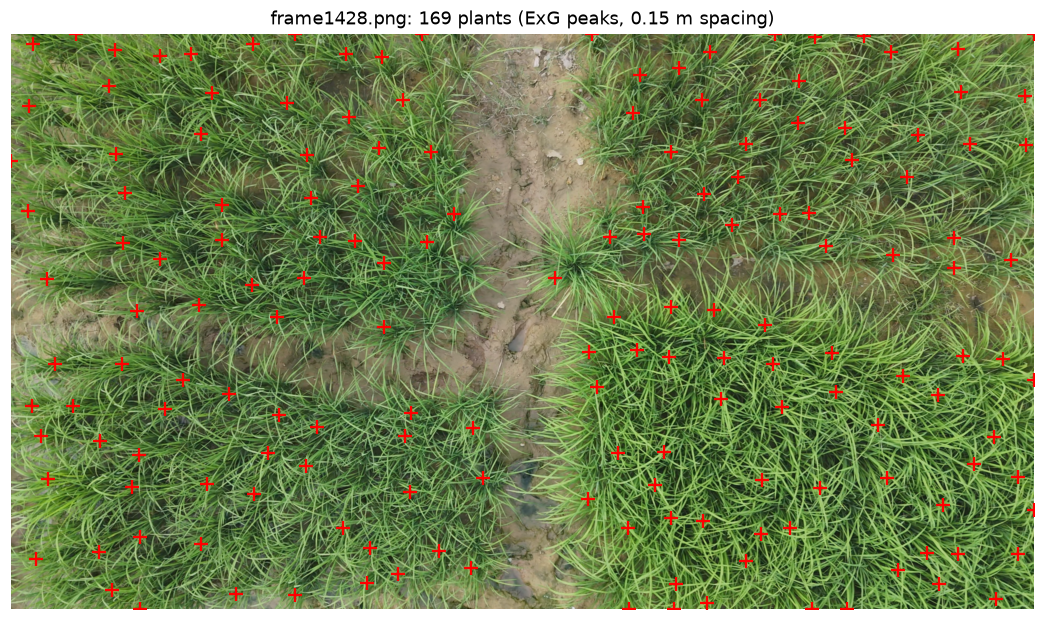

In [3]:
fig, ax = plt.subplots(figsize=(12, 6.8))
ax.imshow(rs.uav.to_rgb_array(img)); ax.plot(pts.col, pts.row, "r+", ms=9, mew=1.5)
ax.set_title(f"{frames[3].name}: {len(pts)} plants (ExG peaks, 0.15 m spacing)"); ax.axis("off")
plt.show()

**Spacing matters more than anything else.** Transplanted rice is commonly set at 15 to 25 cm
between hills. The table runs both detectors over four frames for several spacings:


In [4]:
rows = []
for f in frames[:4]:
    im = rs.uav.read_frame(f, gsd=GSD, max_dim=1920)
    e = rs.uav.vegetation_indices(im, "ExG")
    row = {"frame": f.name}
    for md in [0.10, 0.15, 0.20, 0.25]:
        row[f"peaks {md:.2f} m"] = len(rs.uav.count_plants(e, min_distance_m=md, sigma_m=md / 5, gsd=im.attrs["gsd_m"]))
    row["blobs 0.15 m"] = len(rs.uav.count_plants(e, min_distance_m=0.15, sigma_m=0.03, method="blobs", gsd=im.attrs["gsd_m"]))
    rows.append(row)
sens = pd.DataFrame(rows).set_index("frame")
sens

,peaks 0.10 m,peaks 0.15 m,peaks 0.20 m,peaks 0.25 m,blobs 0.15 m
frame,,,,,
frame1123.png,117,48,32,23,247
frame1278.png,152,67,43,30,215
frame130.png,196,82,49,33,326
frame1428.png,322,169,104,69,534


Counts change by a factor of three or more across plausible spacings, and the
Laplacian-of-Gaussian blob detector, which responds to every leaf cluster, finds far more.
Without reference counts there is no way to know which is right; the only defensible choices
are (a) take the spacing from the planting design and check the overlay by eye, or (b)
calibrate the parameters on a few plots counted by hand, and report the accuracy
$1 - |\hat n - n| / n$ as LUMS did (94.95 % for RiceNet).


## Large images: tiles, stitching and merging

An orthomosaic can be 30 000 × 20 000 pixels; models run on tiles. `rs.uav.sliding_windows`
yields overlapping windows (LUMS: 1024 px tiles, 128 px overlap).


15 tiles of 1024 px with 128 px overlap on a (2160, 3840) frame


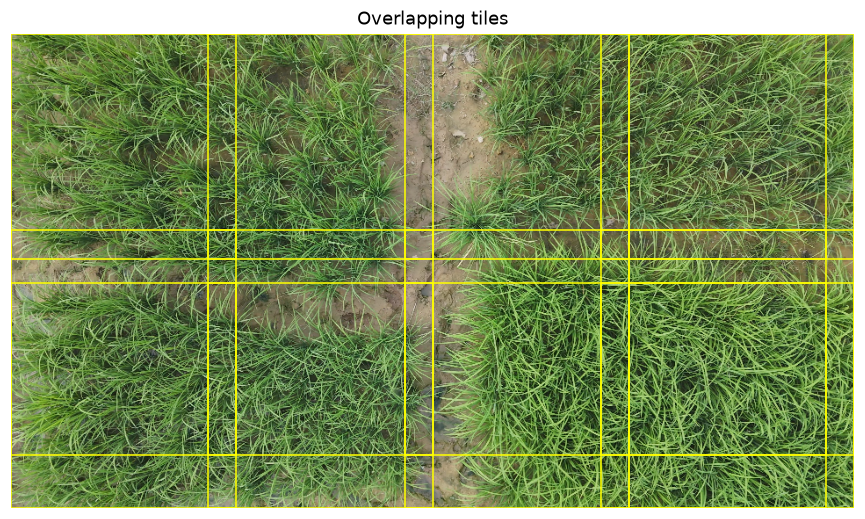

In [5]:
full = rs.uav.read_frame(frames[3], gsd=GSD)  # full resolution, 3840 x 2160
H, W = full.sizes["y"], full.sizes["x"]
wins = list(rs.uav.sliding_windows(H, W, tile=1024, overlap=128))
print(len(wins), "tiles of 1024 px with 128 px overlap on a", (H, W), "frame")

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.imshow(rs.uav.to_rgb_array(full.isel(x=slice(None, None, 4), y=slice(None, None, 4))), extent=[0, W, H, 0])
for r0, c0, h, w in wins:
    ax.add_patch(plt.Rectangle((c0, r0), w, h, fill=False, color="yellow", lw=1))
ax.set_title("Overlapping tiles"); ax.axis("off"); plt.show()

**Stitching.** When a tile-wise output depends on the tile (a model's response near its
borders, or any per-tile normalisation), plain averaging leaves visible seams. Cosine
(Hann) weights give each tile's centre full weight and fade towards its borders, so overlaps
blend smoothly. The demonstration below uses a deliberately tile-dependent function, ExG
rescaled to 0-1 within each tile:


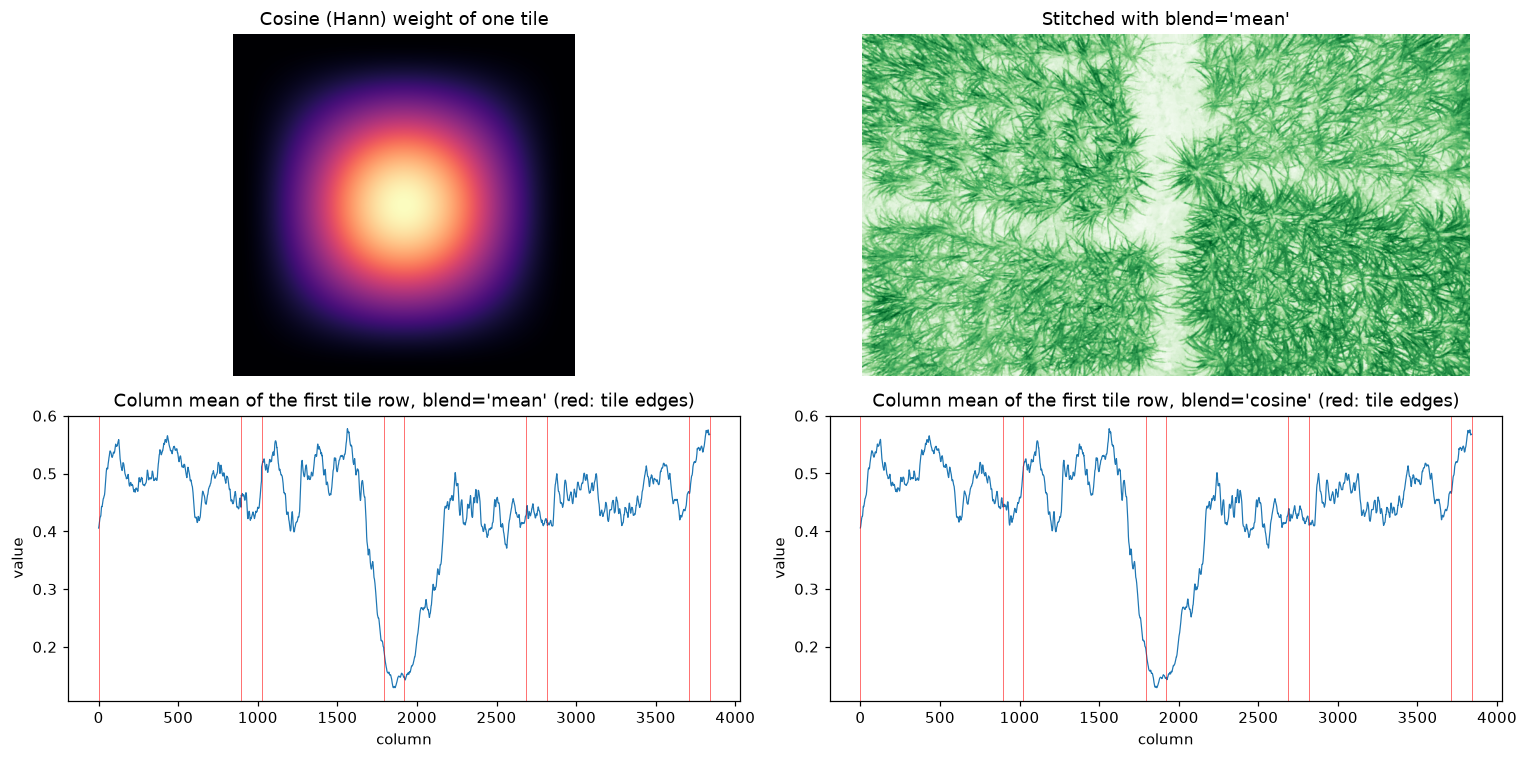

blend='mean': mean jump across inner tile edges = 0.0092
blend='cosine': mean jump across inner tile edges = 0.0018


In [6]:
rgb_full = rs.uav.to_rgb_array(full)

def tile_exg(t):
    """ExG rescaled to 0-1 within the tile: a stand-in for a tile-dependent model output."""
    e = 2 * t[..., 1] - t[..., 0] - t[..., 2]
    return (e - e.min()) / (np.ptp(e) + 1e-9)

stitched = {b: rs.uav.predict_tiled(rgb_full, tile_exg, tile=1024, overlap=128, blend=b) for b in ["mean", "cosine"]}
w = rs.uav.cosine_weight(1024, 1024)
seams = sorted({c0 for _, c0, _, _ in wins} | {c0 + w_ for _, c0, _, w_ in wins})  # tile edges along x

fig, axes = plt.subplots(2, 2, figsize=(14, 7), gridspec_kw={"height_ratios": [1.2, 1]})
axes[0, 0].imshow(w, cmap="magma"); axes[0, 0].set_title("Cosine (Hann) weight of one tile"); axes[0, 0].axis("off")
axes[0, 1].imshow(stitched["mean"][::4, ::4], cmap="Greens"); axes[0, 1].set_title("Stitched with blend='mean'"); axes[0, 1].axis("off")
band = slice(0, 1024)  # the first row of tiles
for ax, b in [(axes[1, 0], "mean"), (axes[1, 1], "cosine")]:
    prof = stitched[b][band].mean(axis=0)
    ax.plot(prof, lw=0.8)
    for sx in seams:
        ax.axvline(sx, color="r", lw=0.6, alpha=0.6)
    ax.set(title=f"Column mean of the first tile row, blend='{b}' (red: tile edges)", xlabel="column", ylabel="value")
plt.tight_layout(); plt.show()

inner = [sx for sx in seams if 0 < sx < W]
for b in ["mean", "cosine"]:
    prof = stitched[b][band].mean(axis=0)
    print(f"blend={b!r}: mean jump across inner tile edges = {np.mean([abs(prof[sx] - prof[sx - 1]) for sx in inner]):.4f}")

With `blend="mean"` the profile steps wherever a tile starts or ends (red lines), because each
tile was rescaled differently. Cosine weights fade each tile out towards its edges, so the
transition is spread over the overlap and the steps are smoothed out. (RiceNet's density maps are
stitched this way.)

A note on the weight itself: the LUMS script builds it from a cosine over half a period,
which makes a ramp that peaks in the tile's bottom-right corner, not a centred window. GeoLattice
uses the full period, as shown in the top-left panel.

**Merging points.** Plants in an overlap are detected by two tiles. `rs.uav.merge_points`
replaces points closer than a radius with their mean.


In [7]:
def tile_peaks(core_only):
    """ExG peaks per tile, in frame pixels; optionally keep only each tile's core."""
    out = []
    for r0, c0, h, w_ in wins:
        t = full.isel(y=slice(r0, r0 + h), x=slice(c0, c0 + w_))
        p = rs.uav.count_plants(rs.uav.vegetation_indices(t, "ExG"), min_distance_m=0.15, sigma_m=0.03, gsd=GSD)
        rr, cc = p.row.to_numpy() + r0, p.col.to_numpy() + c0
        if core_only:  # the half of each overlap nearest a tile belongs to that tile
            half = 128 // 2
            keep = ((rr >= (r0 + half if r0 > 0 else 0)) & (rr < (r0 + h - half if r0 + h < H else H)) &
                    (cc >= (c0 + half if c0 > 0 else 0)) & (cc < (c0 + w_ - half if c0 + w_ < W else W)))
            rr, cc = rr[keep], cc[keep]
        out.append(pd.DataFrame({"row": rr, "col": cc}))
    return pd.concat(out, ignore_index=True)

all_pts = tile_peaks(core_only=False)
merged = rs.uav.merge_points(all_pts, radius=0.15 / GSD / 2, x="col", y="row")  # half the spacing, in pixels
core = tile_peaks(core_only=True)
core_merged = rs.uav.merge_points(core, radius=0.15 / GSD / 2, x="col", y="row")
whole = rs.uav.count_plants(rs.uav.vegetation_indices(full, "ExG"), min_distance_m=0.15, sigma_m=0.03, gsd=GSD)
pd.Series({"whole frame at once": len(whole),
           "all tile points": len(all_pts), "all tile points, merged": len(merged),
           "tile cores only": len(core), "tile cores, merged": len(core_merged)}).to_frame("count")

,count
whole frame at once,171
all tile points,384
"all tile points, merged",216
tile cores only,270
"tile cores, merged",172


Merging alone is not enough: a peak detector also fires on leaves cut by a tile edge, and
those half-plants sit too far from the true centre to be merged. Keeping only each tile's
**core** (dropping detections within half the overlap of an inner edge) removes them, and
merging then has little left to do. RiceNet's `density_count` uses the same idea (its
`border` argument). Small differences from the whole-frame count remain because Otsu picks a
threshold per tile.


## Plant size

RiceNet's second network regresses a size for each plant. A classical stand-in: grow each
detected plant into the vegetation mask with a watershed seeded at the peaks, and take each
region's area. `rs.uav.size_classes` then labels plants small, medium or large by quartiles,
as the LUMS maps do.


,count,mean,std,min,25%,50%,75%,max
size_class,,,,,,,,
large,42.0,1795.4,421.6,1263.5,1443.4,1705.9,2032.8,2891.7
medium,85.0,822.8,219.3,549.4,642.2,753.4,1037.3,1249.2
small,42.0,388.8,144.9,0.0,347.3,431.1,496.9,545.1


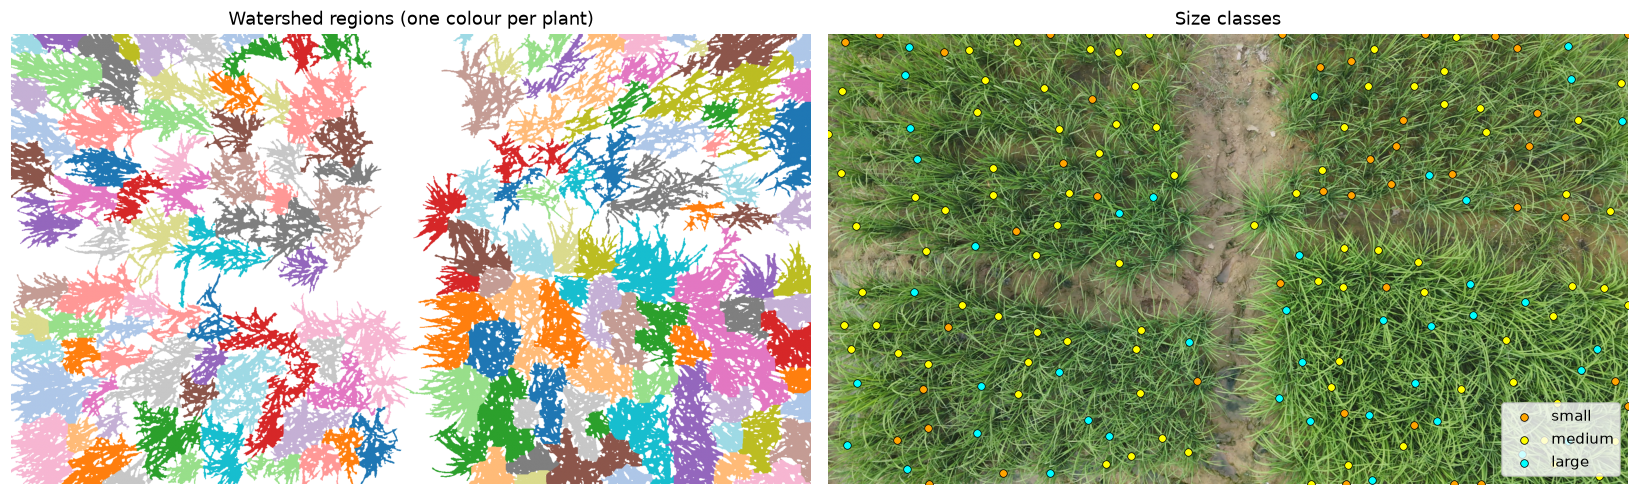

In [8]:
from scipy import ndimage as ndi
from skimage.segmentation import watershed

mask, cover = rs.uav.canopy_cover(exg)
markers = np.zeros(exg.shape, np.int32)
markers[pts.row.to_numpy(), pts.col.to_numpy()] = np.arange(1, len(pts) + 1)
smooth = ndi.gaussian_filter(np.nan_to_num(exg.values), 0.03 / gsd)
regions = watershed(-smooth, markers, mask=mask.values)
area_px = ndi.sum(np.ones_like(regions), regions, index=np.arange(1, len(pts) + 1))
plants = pd.DataFrame({"row": pts.row, "col": pts.col, "size_px": area_px,
                       "area_cm2": area_px * (gsd * 100) ** 2})
plants["size_class"] = rs.uav.size_classes(plants, col="size_px")
display(plants.groupby("size_class").area_cm2.describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].imshow(np.ma.masked_equal(regions, 0) % 20, cmap="tab20"); axes[0].set_title("Watershed regions (one colour per plant)")
axes[1].imshow(rs.uav.to_rgb_array(img))
for cls, c in [("small", "orange"), ("medium", "yellow"), ("large", "cyan")]:
    d = plants[plants.size_class == cls]
    axes[1].scatter(d.col, d.row, s=25, c=c, edgecolors="k", lw=0.5, label=cls)
axes[1].legend(loc="lower right"); axes[1].set_title("Size classes")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## Plants per square metre

`rs.uav.plants_per_area(points, polygons)` counts points per polygon and divides by area. The
frame has no CRS, so a grid of 1 m × 1 m cells is laid out in the frame's own metre
coordinates (with a real orthomosaic, use plot polygons in its CRS; geographic CRSs are
projected to UTM automatically).


       count  area  density
count  21.00  21.0    21.00
mean    5.48   1.0     5.48
std     2.09   0.0     2.09
min     1.00   1.0     1.00
25%     5.00   1.0     5.00
50%     5.00   1.0     5.00
75%     7.00   1.0     7.00
max     9.00   1.0     9.00


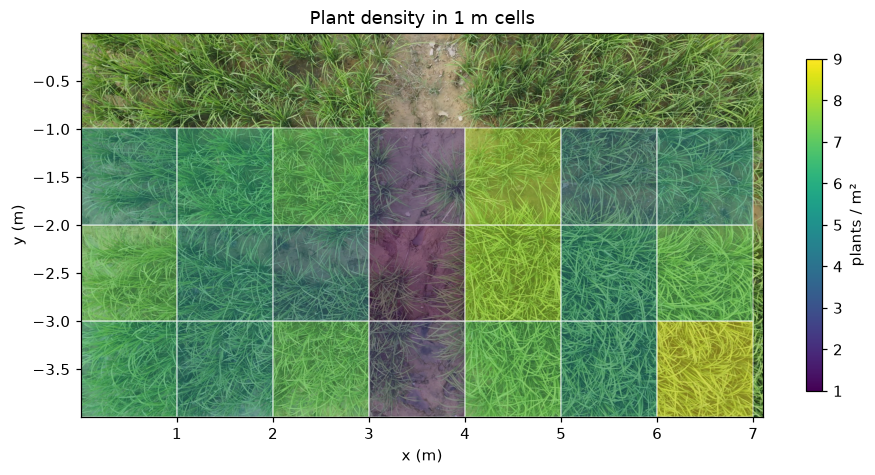

In [9]:
xmin, xmax = float(img.x.min()), float(img.x.max())
ymin, ymax = float(img.y.min()), float(img.y.max())
cells = [box(x, y, x + 1, y + 1) for x in np.arange(xmin, xmax - 1, 1.0) for y in np.arange(ymin, ymax - 1, 1.0)]
grid = gpd.GeoDataFrame({"cell": range(len(cells))}, geometry=cells)
dens = rs.uav.plants_per_area(pts, grid)
print(dens[["count", "area", "density"]].describe().round(2))

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.imshow(rs.uav.to_rgb_array(img), extent=[xmin, xmax, ymin, ymax])
dens.plot(column="density", ax=ax, alpha=0.45, cmap="viridis", edgecolor="w", legend=True,
          legend_kwds={"label": "plants / m²", "shrink": 0.7})
ax.set(title="Plant density in 1 m cells", xlabel="x (m)", ylabel="y (m)"); plt.show()

Cells over the alley between plots have the fewest plants. Note the level, though: about 5 to
9 detected plants per m², while a 20-25 cm transplanting grid would give 16 to 25 hills per
m². Either the peak detector merges neighbouring hills at this spacing, or the 1.85 mm GSD
(reported for the orthomosaic, not for these video frames) is wrong for the frames, which
would change every metric distance and area. A short hand count, as in Exercise 1, settles
which.


## Two dates compared

The same detector on all frames of 22 and 28 August (each date's frames come from different
locations, so compare distributions, not frames):


In [10]:
rows = []
for date in ["2025-08-22", "2025-08-28"]:
    for f in sorted((LUMS / date).glob("*.png")):
        im = rs.uav.read_frame(f, gsd=GSD, max_dim=1920)
        e = rs.uav.vegetation_indices(im, "ExG")
        p = rs.uav.count_plants(e, min_distance_m=0.15, sigma_m=0.03, gsd=im.attrs["gsd_m"])
        area = im.sizes["x"] * im.sizes["y"] * im.attrs["gsd_m"] ** 2
        rows.append({"date": date, "frame": f.name, "plants": len(p), "plants_per_m2": len(p) / area,
                     "cover": rs.uav.canopy_cover(e)[1]})
counts = pd.DataFrame(rows)  # fewer peaks on 28 Aug: neighbouring hills start to merge
display(counts.groupby("date")[["plants", "plants_per_m2", "cover"]].describe().round(2).T)
counts.to_csv(OUT / "plant_counts_classical.csv", index=False)

date                 2025-08-22  2025-08-28
plants        count       10.00       10.00
              mean       103.90       71.80
              std         42.58       15.66
              min         48.00       44.00
              25%         69.50       63.00
              50%         94.00       68.00
              75%        141.00       82.25
              max        169.00       96.00
plants_per_m2 count       10.00       10.00
              mean         3.66        2.53
              std          1.50        0.55
              min          1.69        1.55
              25%          2.45        2.22
              50%          3.31        2.40
              75%          4.97        2.90
              max          5.95        3.38
cover         count       10.00       10.00
              mean         0.43        0.35
              std          0.12        0.07
              min          0.24        0.22
              25%          0.34        0.31
              50%          0.39        0.37
              75%          0.54        0.39
              max          0.60        0.45

## RiceNet density counting

RiceNet (Chaudhry et al. 2026, code in `code/plant_counting_&_size_estimation/`) predicts a
density map whose integral is the plant count; peaks of the map are plant centres. The GeoLattice
port, `rs.uav.density_count`, runs it on 1024 px tiles with 128 px overlap, stitches the
density with cosine weights, finds peaks (`peaks_from_density`) and merges duplicates with
`merge_points`. An optional second network gives plant size.

The weights are on Google Drive. `rs.uav.list_weights()` shows the registry and whether each
file is cached; `rs.uav.fetch_weights("ricenet_count")` downloads it with `gdown`.


In [11]:
rs.uav.list_weights()

,name,task,source,kind,cached
0,sam_vit_b,Segment Anything ViT-B (plant masks),"Kirillov et al. 2023, Apache-2.0",file,False
1,sam_vit_l,Segment Anything ViT-L,"Kirillov et al. 2023, Apache-2.0",file,False
2,sam_vit_h,Segment Anything ViT-H,"Kirillov et al. 2023, Apache-2.0",file,False
3,ricenet_count,RiceNet rice plant counting (density map),"Chaudhry, Rana & Jaleel 2026 (LUMS), MIT",gdrive_folder,False
4,ricenet_size,RiceNet plant size regression,"Chaudhry, Rana & Jaleel 2026 (LUMS), MIT",gdrive_folder,False
5,yolov5_rice_panicle,YOLOv5 rice panicle detection (use backend='yo...,"Chaudhry, Rana & Jaleel 2026 (LUMS), MIT",gdrive_folder,False


In [12]:
if RUN_DL:
    model = rs.uav.load_ricenet(rs.uav.fetch_weights("ricenet_count"), kind="count")
    size_model = rs.uav.load_ricenet(rs.uav.fetch_weights("ricenet_size"), kind="size")
    pts_dl, density = rs.uav.density_count(full, model, size_model=size_model, tile=1024, overlap=128, progress=True)
    pts_dl["size_class"] = rs.uav.size_classes(pts_dl)
    print(len(pts_dl), "plants (RiceNet) vs", len(whole), "(ExG peaks)")
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
    axes[0].imshow(density, cmap="inferno"); axes[0].set_title(f"RiceNet density, integral = {float(density.sum()):.0f}")
    axes[1].imshow(rgb_full); axes[1].plot(pts_dl.col, pts_dl.row, "c+", ms=6)
    for a in axes: a.axis("off")
    plt.show()
else:
    print("RUN_DL is False: RiceNet skipped. Set RUN_DL = True to download weights and compare with ExG peaks.")

RUN_DL is False: RiceNet skipped. Set RUN_DL = True to download weights and compare with ExG peaks.


## Summary and exercises

**Key points**

- Before canopies merge, plants are peaks of Excess Green. Set the minimum spacing from how
  the crop was planted, then check a hand count.
- Large frames are counted in overlapping tiles. Cosine weights hide the seams, and
  `merge_points` drops detections that were counted twice.
- Plant size and plants per square metre turn the points into stand traits.
- RiceNet density counts take over when peaks blur together. The windowing around that model
  is the same tiling machinery.

**GeoLattice functions used:** `rs.uav.count_plants`, `rs.uav.sliding_windows`, `rs.uav.predict_tiled`,
`rs.uav.merge_points`, `rs.uav.size_classes`, `rs.uav.plants_per_area`,
`rs.uav.density_count`, `rs.uav.load_ricenet`.

**Exercises**

1. Count plants by hand in a 1 m × 1 m window of one frame, then pick the `min_distance_m`
   that best reproduces your count. Does it transfer to the other frames?
2. Replace ExG with VARI (clipped to -1..1) in `count_plants`. Which index gives cleaner peaks
   in flooded areas?
3. Run `predict_tiled` with `overlap=0` and `overlap=256`. How do seams and run time change?
4. With `RUN_DL = True`, compute the agreement $1 - |n_{ExG} - n_{RiceNet}| / n_{RiceNet}$ per
   frame.

**References**

- Chaudhry, H., Rana, S. and Jaleel, A. (2026). UAV-based crop reconstruction and trait
  estimation using RGB imagery without external geospatial infrastructure. *Computers and
  Electronics in Agriculture* (accepted).
- Lempitsky, V. and Zisserman, A. (2010). Learning to count objects in images. *NeurIPS*.
- Lindeberg, T. (1998). Feature detection with automatic scale selection. *International
  Journal of Computer Vision*, 30, 79-116 (Laplacian-of-Gaussian blobs).
- Beucher, S. and Meyer, F. (1993). The morphological approach to segmentation: the
  watershed transformation.
